# 1. Quickstart: models, files and photons

xrimodel describes a source as **layers** on the sky, each with its own spectrum, spatial grid and
time behaviour, stored as an **extended SIMPUT** FITS file. A simulator such as XRISALIS only needs
`xrimodel.format`: read the file, sample photons (time, position, energy).

This notebook builds a small scene with the engine, looks at the per-pixel maps, writes and reads
the file, samples a day of photons and measures the reverberation lag of a disc line behind its
driving corona. The last section builds a model by hand, without the engine.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from matplotlib.colors import LogNorm

import xrimodel as xm
from xrimodel.engine import GaussianBlob, PointSource, Scene, ThinDisc


def extent(g):
    # imshow extent for a RegularGrid, East to the left
    return [g.x0 + g.nx / 2 * g.scale, g.x0 - g.nx / 2 * g.scale,
            g.y0 - g.ny / 2 * g.scale, g.y0 + g.ny / 2 * g.scale]

## A scene

A Sgr A*-like geometry (1 r_g ≈ 5 µas at 8.2 kpc for 4.3×10⁶ M☉):

* a point-like **corona** (power law) whose brightness follows a red-noise **driver** (a power
  spectrum realised with a fixed seed);
* a thin Keplerian **disc** emitting a narrow 6.4 keV line, lit by a lamp 10 r_g above the hole, so
  each pixel follows the same driver *delayed* by its light-travel time, and is Doppler and
  gravitationally shifted (map `G`);
* a soft thermal **blob** offset from the centre.

In [2]:
scene = Scene(ra=266.41683, dec=-29.00781, distance_pc=8178.0,
              grid=xm.RegularGrid(nx=160, ny=160, scale=1.5))   # 1.5 uas pixels

f = np.geomspace(1e-5, 2e-2, 400)
scene.add_driver(xm.PSDDriver(f, xm.broken_powerlaw_psd(f, rms=0.4, f_break=2e-4),
                              name="corona", seed=42))
scene.add(PointSource("corona", {"kind": "powerlaw", "gamma": 2.0, "norm": 2e-3}, driver="corona"))
scene.add(ThinDisc("fe_line", {"kind": "gaussian_line", "e0": 6.4, "sigma": 0.003}, flux=3e-4,
                   mass_msun=4.3e6, r_in=6, r_out=30, inclination=60, position_angle=30,
                   h_lamp=10, driver="corona"))
scene.add(GaussianBlob("hot_spot", {"kind": "blackbody", "kt": 0.25, "norm": 5e-4},
                       sigma=15.0, x=80.0, y=-60.0))
model = scene.render()
for layer in model.layers:
    print(f"{layer.name:9s} {layer.kind:9s} {layer.mean_photon_flux():.2e} photons/s/cm^2")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


corona    separable 6.50e-03 photons/s/cm^2
fe_line   specmap   3.00e-04 photons/s/cm^2
hot_spot  separable 3.74e-04 photons/s/cm^2


## Per-pixel maps

The disc is a **SpecMap** layer: one rest-frame template plus per-pixel planes. `NORM` is the photon
flux per pixel, `G` the energy shift (E_obs = G E_rest: blue on the approaching side, red on the
receding side and near the hole), `DELAY` the light-travel delay after the corona. The inner
6 r_g are empty and the outer edge (30 r_g) runs off the grid.

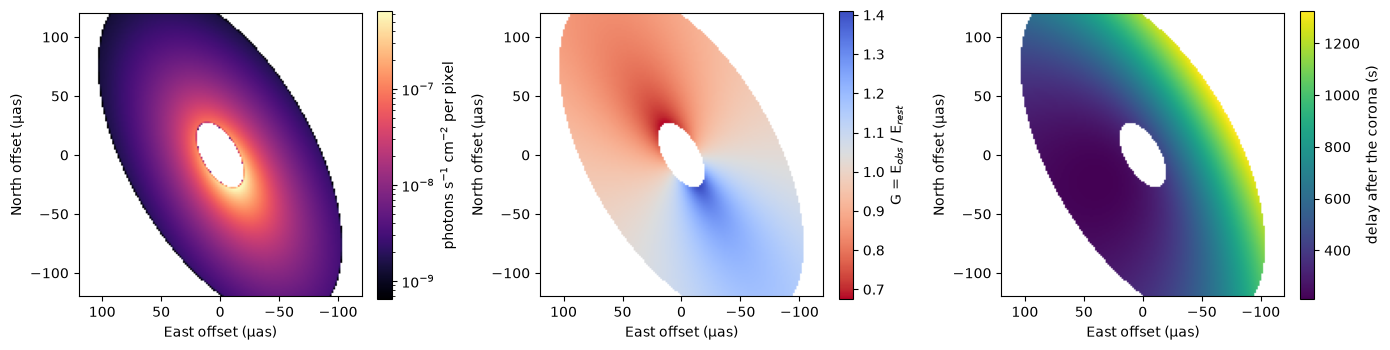

In [3]:
disc = model.layer("fe_line")
g = disc.grid
on = disc.maps["NORM"] > 0
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (key, cmap, lab) in zip(ax, [("NORM", "magma", "photons s$^{-1}$ cm$^{-2}$ per pixel"),
                                    ("G", "coolwarm_r", "G = E$_{obs}$ / E$_{rest}$"),
                                    ("DELAY", "viridis", "delay after the corona (s)")]):
    img = g.to_image(np.where(on, disc.maps[key], np.nan))
    norm = LogNorm(vmin=img[on.reshape(img.shape)].max() * 1e-3) if key == "NORM" else None
    im = a.imshow(img, origin="lower", extent=extent(g), cmap=cmap, norm=norm)
    fig.colorbar(im, ax=a, label=lab, fraction=0.046)
    a.set_xlabel("East offset (µas)"); a.set_ylabel("North offset (µas)")
fig.tight_layout()

## The file

`write_model` writes standard SIMPUT extensions (`SRC_CAT`, spectra, images) that any SIMPUT reader
can use, plus extra columns for what SIMPUT doesn't usually support: `SMAP_*` (SpecMap planes), driver
definitions and the scene description (`MODELSPEC`), from which the scene can be rebuilt.

In [4]:
xm.write_model(model, "quickstart.fits", overwrite=True)
fits.info("quickstart.fits")
model = xm.read_model("quickstart.fits")
rebuilt = Scene.from_spec(model.spec)
print([c.name for c in rebuilt.components])

Filename: quickstart.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       9   ()      
  1  SRC_CAT       1 BinTableHDU     54   3R x 16C   [J, 48A, D, D, E, E, E, E, E, 80A, 80A, 80A, 16A, 64A, D, D]   
  2  SPECTRUM      1 BinTableHDU     23   4R x 4C   [48A, PD(512), PD(512), PD(513)]   
  3  PSD_CORONA    1 BinTableHDU     21   400R x 2C   [D, D]   
  4  IMG_FE_LINE    1 ImageHDU        27   (160, 160)   float32   
  5  SMAP_FE_LINE    1 ImageHDU        42   (160, 160, 7)   float32   
  6  IMG_HOT_SPOT    1 ImageHDU        27   (160, 160)   float32   
  7  MODELSPEC     1 ImageHDU         8   (20821,)   uint8   
['corona', 'fe_line', 'hot_spot']


## Photons

A day on 100 cm² of effective area. Times come from thinning the driver (with each pixel's delay),
energies from the templates shifted by `G`, positions uniformly within each pixel.

61593 photons: {'corona': 55776, 'fe_line': 2605, 'hot_spot': 3212}


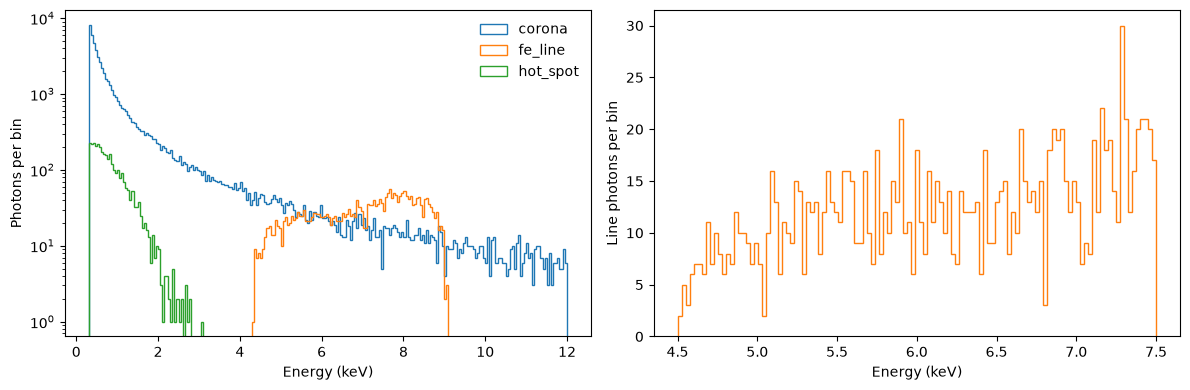

In [5]:
ph = xm.sample_photons(model, 0.0, 86400.0, area=100.0, rng=1)
print(len(ph), "photons:", {n: int((ph.layer == i).sum()) for i, n in enumerate(ph.layer_names)})

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0.3, 12, 235)
for i, name in enumerate(ph.layer_names):
    ax[0].hist(ph.energy[ph.layer == i], bins=bins, histtype="step", label=name)
ax[0].set_yscale("log"); ax[0].set_xlabel("Energy (keV)"); ax[0].set_ylabel("Photons per bin")
ax[0].legend(frameon=False)
fe = ph.layer == ph.layer_names.index("fe_line")
ax[1].hist(ph.energy[fe], bins=np.linspace(4.5, 7.5, 120), histtype="step", color="C1")
ax[1].set_xlabel("Energy (keV)"); ax[1].set_ylabel("Line photons per bin")
fig.tight_layout()

## Reverberation

The line follows the corona with the disc's delays. The cross-correlation of the two light curves
peaks at the mean delay, and `transfer_function` gives the full energy-delay response ψ(E, τ): the
impulse response that spectral-timing codes (e.g. nDspec) turn into lag-energy spectra.

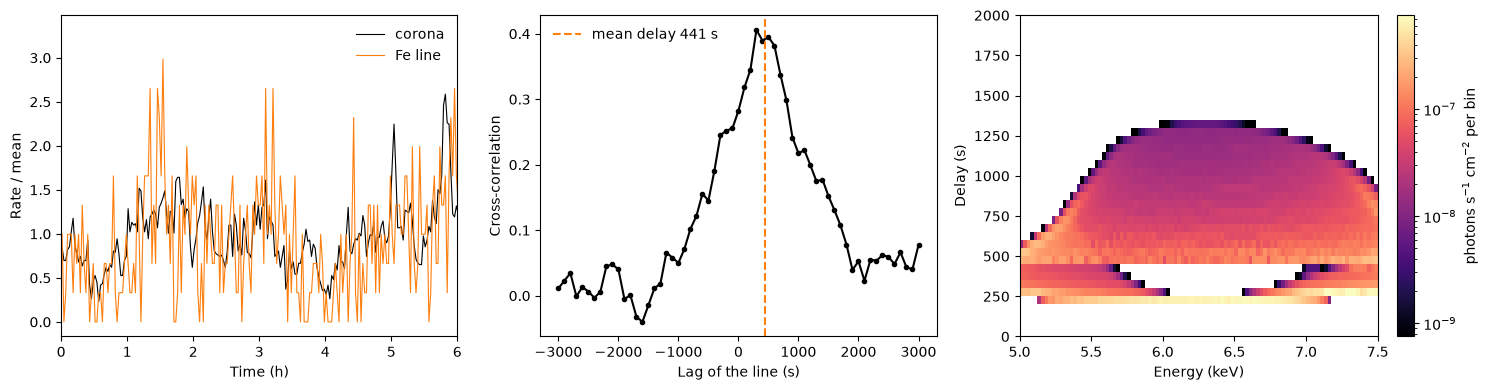

In [6]:
tb = np.arange(0.0, 86400.0 + 1, 100.0)
lc = {}
for name in ("corona", "fe_line"):
    lc[name], _ = np.histogram(ph.time[ph.layer == ph.layer_names.index(name)], tb)
a, b = (lc[k] - lc[k].mean() for k in ("corona", "fe_line"))
lags = np.arange(-30, 31)
cc = [np.corrcoef(a[max(0, -k):a.size - max(0, k)], b[max(0, k):b.size - max(0, -k)])[0, 1]
      for k in lags]
mean_delay = (disc.maps["NORM"] * disc.maps["DELAY"]).sum() / disc.maps["NORM"].sum()

e_edges = np.linspace(5.0, 7.5, 101)
d_edges = np.linspace(0.0, 2000.0, 41)
psi = xm.transfer_function(disc, e_edges, d_edges)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
t = 0.5 * (tb[1:] + tb[:-1]) / 3600
ax[0].plot(t, lc["corona"] / lc["corona"].mean(), "k", lw=0.8, label="corona")
ax[0].plot(t, lc["fe_line"] / lc["fe_line"].mean(), "C1", lw=0.8, label="Fe line")
ax[0].set_xlim(0, 6); ax[0].set_xlabel("Time (h)"); ax[0].set_ylabel("Rate / mean")
ax[0].legend(frameon=False)
ax[1].plot(lags * 100.0, cc, "k.-")
ax[1].axvline(mean_delay, color="C1", ls="--", label=f"mean delay {mean_delay:.0f} s")
ax[1].set_xlabel("Lag of the line (s)"); ax[1].set_ylabel("Cross-correlation")
ax[1].legend(frameon=False)
im = ax[2].imshow(np.where(psi > 0, psi, np.nan).T, origin="lower", aspect="auto", cmap="magma",
                  norm=LogNorm(vmin=psi.max() * 1e-3),
                  extent=[e_edges[0], e_edges[-1], d_edges[0], d_edges[-1]])
fig.colorbar(im, ax=ax[2], label="photons s$^{-1}$ cm$^{-2}$ per bin", fraction=0.046)
ax[2].set_xlabel("Energy (keV)"); ax[2].set_ylabel("Delay (s)")
fig.tight_layout()

## Custom models

While we supply basic primitives, any code can write layers directly, e.g. a ring whose energy shift varies with azimuth, next to a periodically varying point source. Note that image pixels are tangent-plane offsets in µas (x East, y North) from the model's reference position.

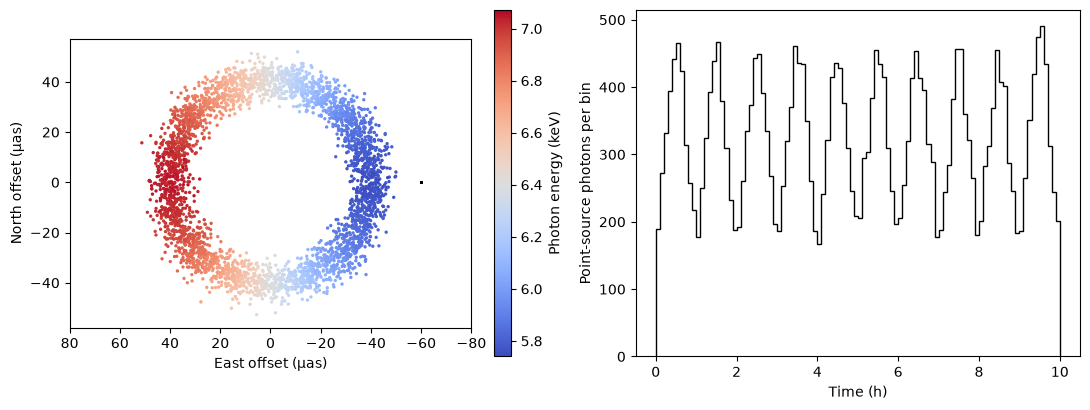

In [7]:
grid = xm.RegularGrid(nx=64, ny=64, scale=2.0)
x, y = grid.centres()
r, phi = np.hypot(x, y), np.arctan2(x, y)
ring = np.exp(-0.5 * ((r - 40.0) / 4.0) ** 2)
e = xm.energy_grid(1.0, 10.0, 0.01)

hand = xm.Model(ra=10.0, dec=-20.0)
hand.add_driver(xm.LightCurve([0.0, 0.5, 1.0], [0.5, 1.5, 0.5], name="orbit",
                              periodic=True, period=3600.0))
hand.add(xm.SeparableLayer("star", xm.powerlaw(e, 2.0, 1e-2), x=-60.0, y=0.0, driver="orbit"))
hand.add(xm.SpecMapLayer("ring", grid, [xm.gaussian_line(e, 6.4, 0.01)],
                         {"NORM": 1e-3 * ring / ring.sum(), "G": 1.0 + 0.1 * np.sin(phi)}))
xm.write_model(hand, "by_hand.fits", overwrite=True)

ph2 = xm.sample_photons(xm.read_model("by_hand.fits"), 0.0, 3.6e4, area=100.0, rng=2)
ringph = ph2.layer == ph2.layer_names.index("ring")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sc = ax[0].scatter(ph2.x[ringph], ph2.y[ringph], c=ph2.energy[ringph], s=2, cmap="coolwarm")
ax[0].plot(ph2.x[~ringph][:300], ph2.y[~ringph][:300], "k.", ms=2)
fig.colorbar(sc, ax=ax[0], label="Photon energy (keV)", fraction=0.046)
ax[0].set_xlim(80, -80); ax[0].set_aspect("equal")
ax[0].set_xlabel("East offset (µas)"); ax[0].set_ylabel("North offset (µas)")
ax[1].hist(ph2.time[~ringph] / 3600, bins=100, histtype="step", color="k")
ax[1].set_xlabel("Time (h)"); ax[1].set_ylabel("Point-source photons per bin")
fig.tight_layout()